In [4]:
import kwant
import numpy as np
import scipy
import matplotlib.pyplot as plt
kwant.plotter.set_engine('matplotlib')

c:\Users\torok\miniconda3\envs\virtual_env\Lib\site-packages\kwant\_plotter.py:77: RuntimeWarning: plotly is not available, if other engines are unavailable, only iterator-providing functions will work
  warnings.warn("plotly is not available, if other engines are unavailable,"


In [5]:
def dos_kernel_polynomial(H, syst):

    R = 5

    Emax, _  = scipy.sparse.linalg.eigsh(H, k=1, which='LA', return_eigenvectors=True)
    Emin, _  = scipy.sparse.linalg.eigsh(H, k=1, which='SA', return_eigenvectors=True)

    corr = 1/R

    a = (Emax - Emin)/(2 - corr)
    b = (Emax + Emin)/2

    H_Tilde = (H - b*np.identity(H.shape[0])) / a

    #print(Emax, Emin)
    #chebyshev basis

    def Cheb_moment(r, H, n):
        T0 = r
        T1 = H @ r

        mu = np.zeros(n)

        mu[0] = np.vdot(r, T0).real

        if(n > 1):
            mu[1] = np.vdot(r,T1).real

        for i in range(2, n):
            Tn = 2 * (H @ T1) - T0
            mu[i] = np.vdot(r, Tn).real
            T0 = T1
            T1 = Tn

        return mu

    def kernel_jackson(D):
        n = np.arange(D)
        return ((D - n + 1) * np.cos(np.pi * n /(D + 1))+ np.sin(np.pi * n / (D + 1)) / np.tan(np.pi /(D + 1))) / (D + 1)

    #random vectors

    D = syst.graph.num_nodes * 2

    Trace = 0

    B = np.identity(D)
    moments = np.zeros(D)

    #print(B.shape)
    for i in range(R):
        E = np.random.normal(size = D) * np.pi
        r = np.dot(B, np.array((np.cos(E) + np.sin(E)*1j)))
        moments += Cheb_moment(r, H_Tilde, D)

    moments = kernel_jackson(D) * moments / R



    nE = 8 * D

    E_ = np.linspace(Emin, Emax, nE).ravel()
    X_ = ((E_ - b) / a).ravel()
    X_ = np.clip(X_, -1 + 1e-12, 1 - 1e-12)

    dos = np.zeros_like(X_)
    n = len(moments)
    for i in range(n - 3):
        dos += moments[i] * np.cos(i * np.arccos(X_))

    dos = dos/(np.pi * np.sqrt(1 - X_**2))

    dos = np.abs(dos)
    return X_ , dos
    #print(np.trace(H))
    #print(moments)

In [37]:
import scipy as sp

def random_vec(len):
    v = np.random.normal(size = len) + np.random.normal(size = len) * 1j
    norm = np.linalg.norm(v)

    return v / norm

def chebyshev_values(x, n):
    T = [1, x]

    for i in range(1, n):
        T_next = 2*x*T[i] - T[i-1]
        T.append(T_next)

    return T

def chebyshev_cosine(x, n):
    return np.cos(n * np.arccos(x))


def fermi(x, B):

    E0 = 0
    return 1  / (np.exp((x - E0)*B) + 1)

def alpha_n_integral(n, B, a = 100):

  if n == 0:
      dn = 1.0
  else:
      dn = 2.0

  dx = 2.0 / a
  x = -1.0 + (np.arange(a) + 0.5) * dx



  alpha_vec = dn * chebyshev_cosine(-x, n) * fermi(x, B) / (np.pi * np.sqrt(1 - x**2))
  return alpha_vec

def beta_n_integral(n, B , a = 100):

  if n == 0:
      dn = 1.0
  else:
      dn = 2.0


  dx = 2.0 / a
  x = -1.0 + (np.arange(a) + 0.5) * dx

  alpha_vec = dn * chebyshev_cosine(x, n) * fermi(x, B) / (np.pi * np.sqrt(1 - x**2))
  return alpha_vec

def convolve_ab(n, m, omega, B, a_points=2048):
  dx = 2.0 / a_points
  x = -1.0 + (np.arange(a_points) + 0.5) * dx

  alpha = alpha_n_integral(n, B, a=a_points)
  beta = beta_n_integral(m, B, a=a_points)

  gamma = signal.fftconvolve(
      alpha, beta, mode="full"
  ) * dx

  # Energy coordinates of the full convolution
  x_conv = 2.0 * x[0] + np.arange(2 * a_points - 1) * dx

  return np.interp(
      -omega, x_conv, gamma, left=0.0, right=0.0
  )

def jackson_kernel(N, n):
    theta = np.pi * n / (N + 1)
    return (
        (N - n + 1) * np.cos(theta)
        + np.sin(theta) / np.tan(np.pi / (N + 1))
    ) / (N + 1)

def kernel_polynomial_2_optical(H, syst, V, omega, n=20, norbs=1, R=10, B = 100):

    Emax = spla.eigsh(
        H, k=1, which="LA", return_eigenvectors=False
    ).item()

    Emin = spla.eigsh(
        H, k=1, which="SA", return_eigenvectors=False
    ).item()
    corr = 1/R

    a = (Emax - Emin)/(2 - corr)
    b = (Emax + Emin)/2

    D = syst.graph.num_nodes * norbs

    I = sp.eye(H.shape[0], format="csr", dtype=H.dtype)

    H_Tilde = (H - b*I) / a

    full_sum = 0

    conv_matrix = {}

    for i in range(n + 1):
        for j in range(n + 1):
            conv_matrix[(i, j)] = convolve_ab(i, j, omega = omega, B = B)

    for vecs_iter in range(R):
        #T(x)
        #approximate with T = 0


        #T(H)
        r = random_vec(D)
        r_L = V @ r
        T0_R = r
        T1_R = H_Tilde @ r
        sum = 0

        T0_L = r_L
        T1_L = H_Tilde @ r_L

        L_moments = [T0_L]
        R_moments = [T0_R]

        for i in range(n):

            R_moments.append(T1_R)
            temp = T1_R
            T1_R = 2* (H_Tilde @ T1_R) - T0_R
            T0_R = temp

        for i in range(n):
            L_moments.append(T1_L)

            temp = T1_L
            T1_L = 2* (H_Tilde @ T1_L) - T0_L
            T0_L = temp


        for i in range(n + 1):
            for j in range(n + 1):
                sum += conv_matrix[(i, j)] * np.vdot(L_moments[j], V @ R_moments[i]) * jackson_kernel(n, i) * jackson_kernel(n, j)
        
        full_sum += sum


    return full_sum / R, Emax, Emin





In [15]:
#pauli matrices

sigma_x = np.array([[0, 1], [1, 0]])
sigma_y = np.array([[0, -1j], [1j, 0]])
sigma_z = np.array([[1, 0], [0, -1]])

In [ ]:
import scipy.sparse as sp
import scipy.sparse.linalg as spla
import scipy.signal as signal

def opt_kpm_system(R = 5, mu = 4, t0 = 0.5, tr = 0.1, epsilon_x = 1, B = 10, J_V = "V", w_frequency = 1001, seed  =  40):


    def current_x_matrix(H, syst, norbs=2):
        x = np.repeat(
            [site.pos[0] for site in syst.sites],
            norbs
        )

        X = sp.diags(x, format="csr")

        Jx = 1j * (H @ X - X @ H)

        return Jx.tocsr()


    def onsite(site, mu):
        # get the position of the site
        x, y = site.pos
        return mu * sigma_z

    rng = np.random.default_rng(seed = seed)

    disorder = {}

    def hopping(site1, site2, t0, tr):
        key = (tuple(site1.tag), tuple(site2.tag))

        if key not in disorder:
            uniform = rng.uniform(-1, 1, size=(2, 2))
            j_uniform = rng.uniform(-1, 1, size=(2, 2))
            disorder[key] = uniform + 1j * j_uniform

        return -t0 * sigma_z + tr * disorder[key]

    def shape(site):
        x, y, = site.pos

        return x*x + y*y < R*R

    template = kwant.Builder(kwant.TranslationalSymmetry(*np.identity(2)))

    lat = kwant.lattice.square(norbs = 2)

    template[lat(0,0)] = onsite

    template[lat(0, 0), lat(0,1)] = hopping
    template[lat(0, 0), lat(1,0)] = hopping
    print(type(lat(0, 0)))

    syst = kwant.Builder()
    syst.fill(template, shape, (0,0));

    Bloch = kwant.wraparound.wraparound(template, keep = None)
    Bloch = Bloch.finalized()

    syst = syst.finalized()

    H_0 = syst.hamiltonian_submatrix(
        params={"mu": mu, "t0": t0, "tr": 0.0},
        sparse=True
    ).tocsr()

    H_total = syst.hamiltonian_submatrix(
        params={"mu": mu, "t0": t0, "tr": tr},
        sparse=True
    ).tocsr()

    num_sites = syst.graph.num_nodes

    J_total = current_x_matrix(H_total, syst)
    J_0 = current_x_matrix(H_0, syst)

    V = sp.kron(
        sp.eye(num_sites, dtype=complex, format="csr"),
        epsilon_x * sigma_x,
        format="csr"
    )

    w = np.linspace((-2 + 1e-12), 2 - 1e-12, w_frequency)

    R_avg = 200
    if(J_V == "V"):
        opt_0, Emax_0, Emin_0 = kernel_polynomial_2_optical(H_0, syst, V, omega = w, n = 50, norbs = 2, R = R_avg, B = B)
        opt, Emax_1, Emin_1 = kernel_polynomial_2_optical(H_total, syst, V, omega = w, n = 50, norbs = 2, R = R_avg, B = B)
    elif(J_V == "J"):
        opt_0, Emax_0, Emin_0 = kernel_polynomial_2_optical(H_0, syst, J_0, omega = w, n = 50, norbs = 2, R = R_avg, B = B)
        opt, Emax_1, Emin_1 = kernel_polynomial_2_optical(H_total, syst, J_total, omega = w, n = 50, norbs = 2, R = R_avg, B = B)

    J_diff = J_total - J_0

    return opt_0, opt, syst, Emax_0, Emin_0, Emax_1, Emin_1, w

def plot_optical_comparison(opt, opt_0, Emax, Emin, Emax_0, Emin_0, w, R_avg=200, cutoff=0.1, title_text = "", Thermal_factor = True, B = 100):


    a = (Emax - Emin) / (2 - 1 / R_avg)
    a_0 = (Emax_0 - Emin_0) / (2 - 1 / R_avg)

    omega = w * a
    omega_0 = w * a_0

    mask = omega > cutoff
    mask_0 = omega_0 > cutoff

    plot_opt = np.real(opt[mask])
    plot_opt_0 = np.real(opt_0[mask_0])

    
    if(Thermal_factor):
        thermal_factor_0 = -np.expm1(-B * omega_0[mask])
        thermal_factor = -np.expm1(-B * omega[mask])
        plot_opt *= thermal_factor
        plot_opt_0 *= thermal_factor_0


    fig, ax = plt.subplots(1, 1, figsize=(13, 4))

    
    ax.plot(omega[mask], plot_opt / omega[mask],
               label="Perturbed")
    ax.plot(omega_0[mask_0], plot_opt_0 / omega_0[mask_0],
               label="Unperturbed")
    ax.set_xlabel(r"Physical frequency $\Omega$")
    ax.set_ylabel(r"$|C(\Omega)|/\Omega$")
    ax.legend()
    ax.grid()
    ax.set_title(title_text)
    plt.tight_layout()
    plt.show()
    plt.figure(figsize=(8, 4))

<class 'kwant.builder.Site'>
||J_0|| = 33.823069050575526
||J_total|| = 34.05209539356336
||J_total - J_0|| = 3.8765192819604803
||J_diff|| = 3.8765192819604803


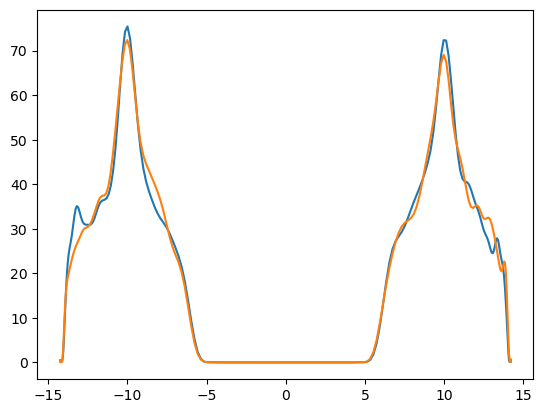

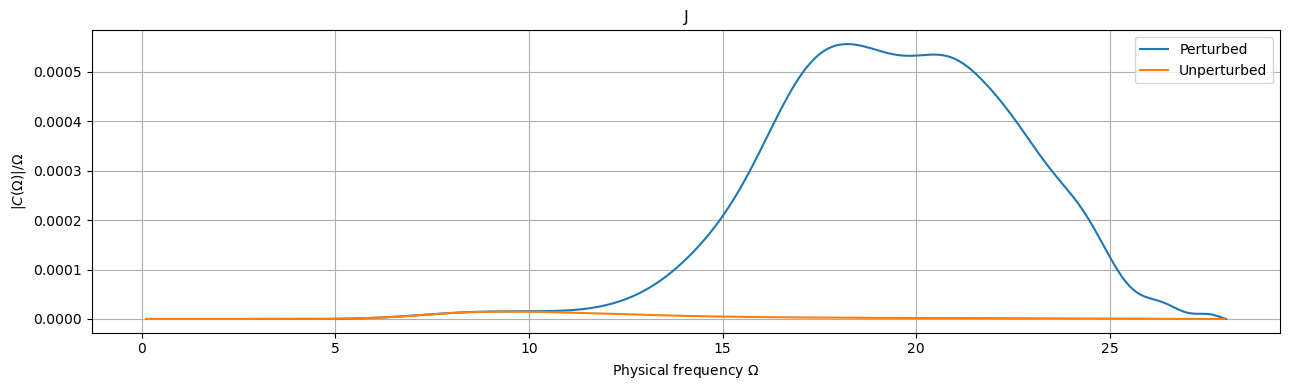

<Figure size 800x400 with 0 Axes>

In [96]:
mu = 10
t0 = 1
tr = 0.1
B = 100


opt_0, opt, syst, Emax_0, Emin_0, Emax_1, Emin_1, w = opt_kpm_system(R = 10, mu = mu, t0 = t0, tr = tr, epsilon_x = 1, B = B, J_V = "J", w_frequency = 1001)


spectrum = kwant.kpm.SpectralDensity(syst, params={"mu": mu, "t0": t0, "tr": 0.0})
energies, densities = spectrum()
plt.plot(energies, densities)

spectrum = kwant.kpm.SpectralDensity(syst, params={"mu": mu, "t0": t0, "tr": tr})
energies, densities = spectrum()
plt.plot(energies, densities)

plot_optical_comparison(
    opt, opt_0,
    Emax_1, Emin_1,
    Emax_0, Emin_0, 
    w, title_text = "J",
    Thermal_factor = True, B = B
)

